<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3c_duais_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio III (c): girar e deslizar no tempo

## O movimento de parafuso, o pêndulo de Wilberforce, e derivadas de trajetórias pela exponencial de uma matriz dual

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 3](X3_duais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3_duais.ipynb)) · **Anterior:** [X3b_duais_sistemas.ipynb](X3b_duais_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3b_duais_sistemas.ipynb)) · **Próximo:** [X3d_duais_perseguicao.ipynb](X3d_duais_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3d_duais_perseguicao.ipynb))

**Objetivo.** Estudar o movimento de um corpo que gira e desliza em torno de **um** eixo fixo, o grupo $SO(2)\times\mathbb R$ do notebook III(a):
- a **cinemática**: com velocidades constantes de giro e de deslizamento, cada ponto do corpo descreve uma **hélice**, e o movimento inteiro é um **parafuso**. É a $\mathrm{Exp}$ do domínio;
- a **dinâmica**: o **pêndulo de Wilberforce**, uma massa pendurada numa mola helicoidal que, ao esticar, também torce. A energia passa do sobe-e-desce para o giro e volta, num batimento que o `sympy` resolve exatamente;
- a **sensibilidade da trajetória**: quanto o movimento muda se um parâmetro mudar. Passando números duais pelo Runge–Kutta, e pela exponencial de uma **matriz dual**, que é a matriz em blocos do notebook I(c) com outro nome.

No fim, como nos domínios anteriores, as matrizes $\mathbf F$ e $\mathbf Q$ do filtro da etapa (d), agora com um ângulo no estado.

**Roteiro**
1. Cinemática: o parafuso e a hélice
2. O pêndulo de Wilberforce: equações pelo `sympy`, modos normais e batimento
3. Runge–Kutta, energia e o caso RKMK = RK4
4. Sensibilidade da trajetória: duais pelo RK4 e a exponencial de uma matriz dual
5. Espaço de estados para a etapa (d)
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy.linalg import expm
from scipy.integrate import solve_ivp
rng = np.random.default_rng(33)

class Dual:
    """Número dual re + ε·du (notebook III(a)); re e du podem ser floats ou arrays."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

---

## 1. Cinemática: o parafuso e a hélice

Um corpo preso a um eixo (o eixo $z$) por uma junta cilíndrica tem dois graus de liberdade: o ângulo $\theta$ e a altura $d$. Com velocidade angular $\omega$ e velocidade axial $v$ constantes, depois de um tempo $t$,

$$\theta(t)=\theta_0+\omega t,\qquad d(t)=d_0+vt .$$

Um ponto do corpo a uma distância $r$ do eixo descreve a curva $\big(r\cos\theta(t),\ r\sin\theta(t),\ d(t)\big)$: uma **hélice**, com **passo** $p=2\pi v/\omega$ (o quanto ela sobe a cada volta). Todo movimento com velocidade constante deste domínio é um **parafuso**, e é isso que a $\mathrm{Exp}$ do notebook III(a) produz. No domínio VII, um teorema clássico (de Chasles) dirá que **qualquer** movimento rígido no espaço é um parafuso em torno de algum eixo; aqui, o eixo é sempre o mesmo.

O `sympy` calcula a velocidade e a aceleração de um ponto da hélice. A aceleração aponta para o eixo, com módulo $r\omega^2$: é a aceleração centrípeta, e o deslizamento uniforme não contribui.

velocidade: [-omega*r*sin(omega*t), omega*r*cos(omega*t), v] ;  |v| = sqrt(omega**2*r**2 + v**2)
aceleração: [-omega**2*r*cos(omega*t), -omega**2*r*sin(omega*t), 0] ;  |a| = omega**2*r
passo da hélice (subida por volta): 2*pi*v/omega
comprimento de uma volta: 2*pi*sqrt(omega**2*r**2 + v**2)/omega  (Pitágoras: a volta 2πr e a subida, num triângulo)


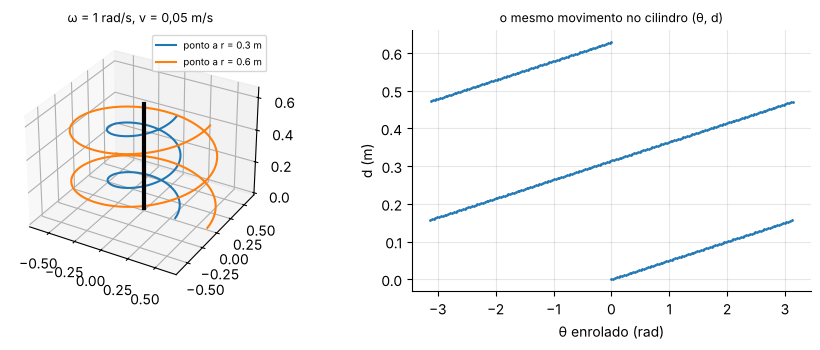

In [2]:
t, r, w, v = sp.symbols("t r omega v", positive=True)
ponto = sp.Matrix([r * sp.cos(w * t), r * sp.sin(w * t), v * t])
vel, acel = ponto.diff(t), ponto.diff(t, 2)
print("velocidade:", list(vel), ";  |v| =", sp.simplify(sp.sqrt(vel.dot(vel))))
print("aceleração:", list(acel), ";  |a| =", sp.simplify(sp.sqrt(acel.dot(acel))))
print("passo da hélice (subida por volta):", sp.simplify(v * 2 * sp.pi / w))
comp = sp.integrate(sp.sqrt(vel.dot(vel)), (t, 0, 2 * sp.pi / w))
print("comprimento de uma volta:", sp.simplify(comp), " (Pitágoras: a volta 2πr e a subida, num triângulo)")

ax = plt.figure(figsize=(9, 3.6)).add_subplot(1, 2, 1, projection="3d")
tt = np.linspace(0, 4 * np.pi, 400)
for rr, cor in [(0.3, "tab:blue"), (0.6, "tab:orange")]:
    ax.plot(rr * np.cos(tt), rr * np.sin(tt), 0.05 * tt, color=cor, label=f"ponto a r = {rr} m")
ax.plot([0, 0], [0, 0], [0, 0.65], "k", lw=3); ax.set_title("ω = 1 rad/s, v = 0,05 m/s", fontsize=9); ax.legend(fontsize=7)
ax2 = plt.gcf().add_subplot(1, 2, 2)
ax2.plot(wrap(tt), 0.05 * tt, ".", ms=2); ax2.set_xlabel("θ enrolado (rad)"); ax2.set_ylabel("d (m)")
ax2.set_title("o mesmo movimento no cilindro (θ, d)", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** À direita, o mesmo movimento no **espaço de estados** $(\theta,d)$, com $\theta$ enrolado: uma reta inclinada que, ao chegar a $\theta=\pi$, reaparece em $-\pi$. É o cilindro do notebook III(a) "desenrolado" num retângulo cujos lados esquerdo e direito são o mesmo lugar.

---

## 2. O pêndulo de Wilberforce

Uma massa $m$ pendurada numa mola helicoidal sobe e desce (altura $z$, medida a partir do equilíbrio) e gira (ângulo $\theta$). Uma mola helicoidal tem uma propriedade curiosa: **esticá-la a torce, e torcê-la a estica**. A energia potencial tem um termo que mistura as duas coordenadas:

$$V=\tfrac12kz^2+\tfrac12\delta\,\theta^2+\tfrac12\epsilon\,z\theta,$$

com $k$ a rigidez axial, $\delta$ a de torção e $\epsilon$ o acoplamento. A energia cinética é $T=\tfrac12m\dot z^2+\tfrac12I\dot\theta^2$, com $I$ o momento de inércia em torno do eixo. Este é o **pêndulo de Wilberforce** (1894): solta-se a massa esticada, sem girar, e depois de alguns segundos ela está girando quase sem subir e descer; depois, volta a subir e descer sem girar, e assim por diante.

O `sympy` monta as equações de Lagrange, $\frac{d}{dt}\frac{\partial L}{\partial\dot q}-\frac{\partial L}{\partial q}=0$, com $L=T-V$.

**Os números.** Valores típicos de um pêndulo de laboratório: $m=0{,}5$ kg, $I=10^{-4}$ kg·m², $k=5$ N/m, $\delta=10^{-3}$ N·m/rad, $\epsilon=10^{-2}$ N. O $\delta$ foi escolhido para que as frequências naturais **sem acoplamento** sejam iguais, $k/m=\delta/I$: é a "sintonia" que faz a troca de energia ser completa.

In [3]:
tt_ = sp.Symbol("t")
m_, I_, k_, dl_, ep_ = sp.symbols("m I k delta epsilon", positive=True)
z, th = sp.Function("z")(tt_), sp.Function("theta")(tt_)
T_cin = sp.Rational(1, 2) * m_ * z.diff(tt_)**2 + sp.Rational(1, 2) * I_ * th.diff(tt_)**2
V_pot = sp.Rational(1, 2) * k_ * z**2 + sp.Rational(1, 2) * dl_ * th**2 + sp.Rational(1, 2) * ep_ * z * th
L = T_cin - V_pot
eqs = [sp.simplify(sp.diff(L.diff(q.diff(tt_)), tt_) - L.diff(q)) for q in (z, th)]
for q, e in zip(("z", "θ"), eqs):
    print(f"equação de {q}:  {e} = 0")

# modos normais: M q'' + K q = 0  →  ω² são os autovalores de M⁻¹K
Mm = sp.diag(m_, I_); Km = sp.Matrix([[k_, ep_ / 2], [ep_ / 2, dl_]])
valores = {m_: sp.Rational(1, 2), I_: sp.Rational(1, 10000), k_: 5, dl_: sp.Rational(1, 1000), ep_: sp.Rational(1, 100)}
w2 = list((Mm.inv() * Km).subs(valores).eigenvals().keys())
w_modos = sorted(float(sp.sqrt(x)) for x in w2)
print("\nfrequências dos modos normais (rad/s):", [round(x, 5) for x in w_modos], "  sem acoplamento:", float(sp.sqrt(sp.Rational(10))))
T_bat = 2 * np.pi / (w_modos[1] - w_modos[0])
print(f"período do batimento 2π/(ω₂ − ω₁) = {T_bat:.2f} s: o tempo para a energia ir do sobe-e-desce ao giro e voltar")

equação de z:  epsilon*theta(t)/2 + k*z(t) + m*Derivative(z(t), (t, 2)) = 0
equação de θ:  I*Derivative(theta(t), (t, 2)) + delta*theta(t) + epsilon*z(t)/2 = 0

frequências dos modos normais (rad/s): [3.04842, 3.27217]   sem acoplamento: 3.1622776601683795
período do batimento 2π/(ω₂ − ω₁) = 28.08 s: o tempo para a energia ir do sobe-e-desce ao giro e voltar


**A solução exata.** As equações são lineares, com coeficientes constantes. Na forma de primeira ordem, $\dot{\mathbf y}=\mathbf A\mathbf y$ com $\mathbf y=(z,\theta,\dot z,\dot\theta)$, a solução é $\mathbf y(t)=e^{\mathbf At}\mathbf y_0$ (notebook I(c)). Solta-se a massa 10 cm abaixo do equilíbrio, sem girar.

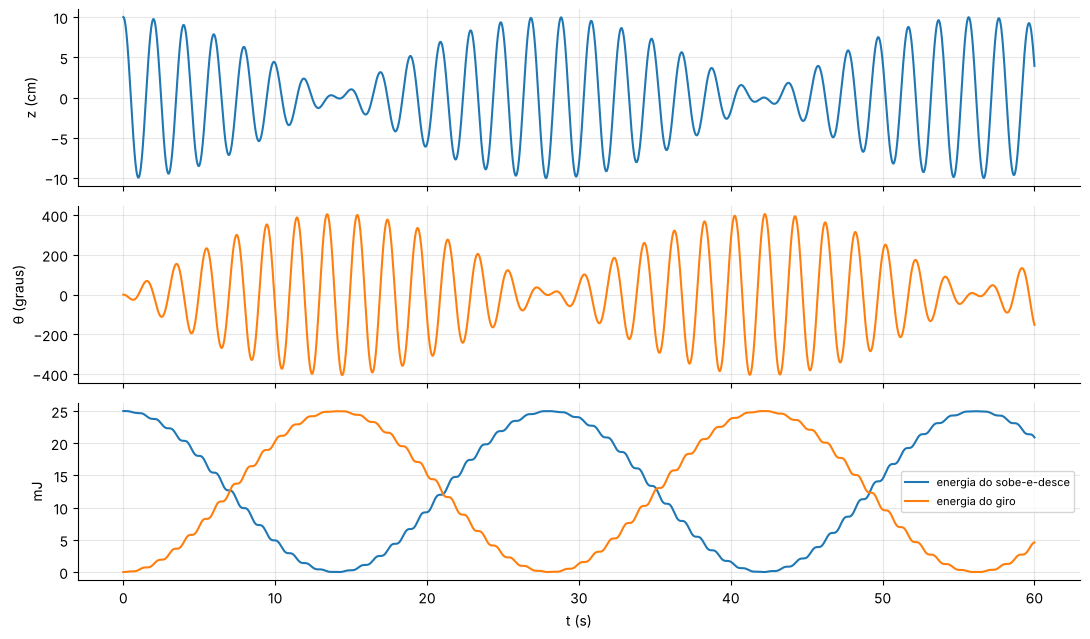

giro máximo: 405°;  a energia passa toda para o giro em t ≈ 14.0 s (metade do batimento: 14.0 s), com 99.9% da energia inicial no giro


In [4]:
M_V, I_V, K_V, DL_V, EP_V = 0.5, 1e-4, 5.0, 1e-3, 1e-2

def matriz_A(ep=EP_V):
    Minv = np.diag([1 / M_V, 1 / I_V])
    Kq = np.array([[K_V, ep / 2], [ep / 2, DL_V]])
    return np.block([[np.zeros((2, 2)), np.eye(2)], [-Minv @ Kq, np.zeros((2, 2))]])

A = matriz_A()
y0 = np.array([0.1, 0.0, 0.0, 0.0])
ts = np.linspace(0, 60, 3000)
Y = np.array([expm(A * ti) @ y0 for ti in ts])
E_axial = 0.5 * M_V * Y[:, 2]**2 + 0.5 * K_V * Y[:, 0]**2
E_giro = 0.5 * I_V * Y[:, 3]**2 + 0.5 * DL_V * Y[:, 1]**2

fig, ax = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(ts, 100 * Y[:, 0]); ax[0].set_ylabel("z (cm)")
ax[1].plot(ts, np.degrees(Y[:, 1]), color="tab:orange"); ax[1].set_ylabel("θ (graus)")
ax[2].plot(ts, 1000 * E_axial, label="energia do sobe-e-desce"); ax[2].plot(ts, 1000 * E_giro, label="energia do giro")
ax[2].set_ylabel("mJ"); ax[2].set_xlabel("t (s)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
k_troca = np.argmax(E_giro[ts < T_bat])
print(f"giro máximo: {np.degrees(np.abs(Y[:, 1]).max()):.0f}°;  a energia passa toda para o giro em t ≈ {ts[k_troca]:.1f} s "
      f"(metade do batimento: {T_bat / 2:.1f} s), com {100 * E_giro[k_troca] / E_axial[0]:.1f}% da energia inicial no giro")

**Leitura.** No começo, toda a energia está no sobe-e-desce; na metade do período de batimento, quase toda está no giro (a massa gira de um lado para o outro, várias voltas, quase sem subir e descer); depois volta. É a mesma física de dois pêndulos acoplados por uma mola fraca, ou de duas cordas de violão afinadas na mesma nota: com frequências iguais, um acoplamento pequeno basta para transferir **toda** a energia, só que devagar.

O ângulo chega a centenas de graus, mais de uma volta para cada lado. Como no notebook III(b), a mola **conta as voltas**: $\theta$ é um número real, e não se enrola.

---

## 3. Runge–Kutta, energia e o caso RKMK = RK4

O RK4 do notebook I(c) integra o pêndulo de Wilberforce sem mudança. A célula mede a ordem contra a solução exata $e^{\mathbf At}\mathbf y_0$ e confere a conservação da energia total (sem atrito, ela deve ficar constante).

In [5]:
def rk4_passo(f, t, y, h):
    k1 = f(t, y); k2 = f(t + h / 2, y + h / 2 * k1); k3 = f(t + h / 2, y + h / 2 * k2); k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4(f, y0, T, h):
    y = y0
    for i in range(int(round(T / h))):
        y = rk4_passo(f, i * h, y, h)
    return y

f_wil = lambda t, y: A @ y
T_fim = 20.0
y_exato = expm(A * T_fim) @ y0
hs = np.array([0.04, 0.02, 0.01, 0.005])
erros = [np.linalg.norm(rk4(f_wil, y0, T_fim, h)[:2] - y_exato[:2]) for h in hs]
ordem = np.polyfit(np.log(hs), np.log(erros), 1)[0]
print("erros em (z, θ) após 20 s:", [f"{e:.1e}" for e in erros], f"  ordem medida = {ordem:.2f}")
confere("ordem do RK4 ≈ 4", ordem, 4.0, tol=0.15)

energia = lambda y: 0.5 * M_V * y[2]**2 + 0.5 * I_V * y[3]**2 + 0.5 * K_V * y[0]**2 + 0.5 * DL_V * y[1]**2 + 0.5 * EP_V * y[0] * y[1]
y = y0.copy(); h = 0.01; E0 = energia(y0)
for i in range(int(60 / h)):
    y = rk4_passo(f_wil, 0, y, h)
print(f"energia relativa depois de 60 s com h = 0,01 s: {energia(y) / E0:.8f}")
confere("RK4 conserva a energia em 60 s (a menos de 10⁻⁶)", energia(y) / E0, 1.0, tol=1e-6)

erros em (z, θ) após 20 s: ['7.0e-04', '4.3e-05', '2.6e-06', '1.6e-07']   ordem medida = 4.02
OK   ordem do RK4 ≈ 4:  diferença máxima = 2.26e-02
energia relativa depois de 60 s com h = 0,01 s: 0.99999991
OK   RK4 conserva a energia em 60 s (a menos de 10⁻⁶):  diferença máxima = 8.58e-08


### RKMK = RK4 neste domínio

O notebook I(c) anunciou: nos domínios com rotação, o Runge–Kutta de Munthe-Kaas (RKMK) atualiza o estado por $\boxplus$, e não por $+$. Neste domínio, o $\boxplus$ do giro **enrola** o ângulo. Como o grupo $SO(2)\times\mathbb R$ é **comutativo**, os colchetes de Lie do RKMK são zero, e enrolar a cada passo deve dar o mesmo que integrar sem enrolar e enrolar só no fim.

A célula confere isso num caso em que o enrolamento importa: uma barra **sem mola de torção** (só com atrito viscoso no giro e uma mola no deslizamento), que recebe um impulso de giro e dá várias voltas até parar. Sem mola de torção, o ângulo é um ponto do círculo, e guardá-lo enrolado é natural.

In [6]:
C_GIRO, I_B, M_B, K_DESL = 0.02, 0.01, 1.0, 4.0

def f_barra(t, y):
    th, d, w, vd = y
    return np.array([w, vd, -C_GIRO / I_B * w, -K_DESL / M_B * d])

def rkmk_cilindro(y0, T, h):
    """RK4 com o estado no cilindro: as inclinações são vetores; o estado avança por ⊞ (enrolando o ângulo)."""
    y = np.array(y0, float)
    mais = lambda y, d: np.array([wrap(y[0] + d[0]), y[1] + d[1], y[2] + d[2], y[3] + d[3]])
    for i in range(int(round(T / h))):
        k1 = f_barra(0, y); k2 = f_barra(0, mais(y, h / 2 * k1)); k3 = f_barra(0, mais(y, h / 2 * k2)); k4 = f_barra(0, mais(y, h * k3))
        y = mais(y, h / 6 * (k1 + 2 * k2 + 2 * k3 + k4))
    return y

y0b = np.array([0.0, 0.1, 20.0, 0.0])                 # impulso de 20 rad/s no giro
y_rk = rk4(f_barra, y0b, 15.0, 0.01)
y_mk = rkmk_cilindro(y0b, 15.0, 0.01)
print(f"RK4 sem enrolar: θ = {y_rk[0]:.6f} rad ({y_rk[0] / (2 * np.pi):.2f} voltas);  enrolado no fim: {wrap(y_rk[0]):.12f}")
print(f"RKMK (enrolando a cada passo):                          {y_mk[0]:.12f}")
confere("RKMK no cilindro = RK4 enrolado no fim (o grupo é comutativo)", [wrap(y_rk[0]), *y_rk[1:]], y_mk, tol=1e-10)

RK4 sem enrolar: θ = 10.000000 rad (1.59 voltas);  enrolado no fim: -2.566370614360
RKMK (enrolando a cada passo):                          -2.566370614360
OK   RKMK no cilindro = RK4 enrolado no fim (o grupo é comutativo):  diferença máxima = 0.00e+00


**Leitura.** A barra dá pouco mais de uma volta e meia antes de parar (10 rad: a velocidade inicial vezes a constante de tempo do atrito, $I/c$), e o RKMK coincide com o RK4 enrolado no fim, neste caso até o último dígito. A partir do domínio V, com posição e atitude no plano, os incrementos de giro e de translação deixam de comutar, e os dois métodos passam a diferir.

---

## 4. Sensibilidade da trajetória

Quanto a trajetória do pêndulo de Wilberforce muda se o acoplamento $\epsilon$ for um pouco diferente? Esta pergunta, a **sensibilidade** $\partial\mathbf y(t)/\partial\epsilon$, aparece em todo ajuste de modelo a dados (o notebook III(b) fez isso com equilíbrios), e é o jacobiano que um filtro de Kalman estendido precisaria se $\epsilon$ fosse um estado a estimar.

**Dois caminhos, que devem concordar.**
1. **Duais pelo RK4:** rodar o RK4 com $\epsilon+\varepsilon$. A classe `Dual` passa pelo integrador sem que ele saiba (o estado é um par de arrays, a parte real e a parte dual).
2. **A exponencial de uma matriz dual.** A solução é $e^{\mathbf A(\epsilon)t}\mathbf y_0$. Com $\epsilon$ dual, a matriz é dual: $\mathbf A_0+\varepsilon\mathbf A_1$, com $\mathbf A_1=\partial\mathbf A/\partial\epsilon$. E a exponencial de uma matriz dual se calcula pela representação do notebook III(a), agora com **matrizes** no lugar de números:
$$\exp\begin{bmatrix}\mathbf A_0&\mathbf A_1\\\mathbf 0&\mathbf A_0\end{bmatrix}t=\begin{bmatrix}e^{\mathbf A_0t}&\mathbf L(t)\\\mathbf 0&e^{\mathbf A_0t}\end{bmatrix},$$
em que o bloco $\mathbf L(t)$ é a derivada de $e^{\mathbf At}$ em relação a $\epsilon$. É a mesma matriz em blocos que o truque de Van Loan usa para discretizar (notebook I(c), seção 5): aquele truque é, sem dizer o nome, aritmética de números duais com matrizes.

sensibilidade ∂y(10 s)/∂ε, duais pelo RK4:  [   -9.868204   -39.559837     4.92761  -1076.959812]
sensibilidade ∂y(10 s)/∂ε, expm da matriz dual: [   -9.868204   -39.559837     4.92761  -1076.959812]
OK   duais pelo RK4 = exponencial da matriz dual:  diferença relativa máxima = 9.73e-12
OK   parte real dos duais = solução exata:  diferença relativa máxima = 8.53e-12
diferenças finitas (h = 1e-7) erram 1.0e-09 (relativo)


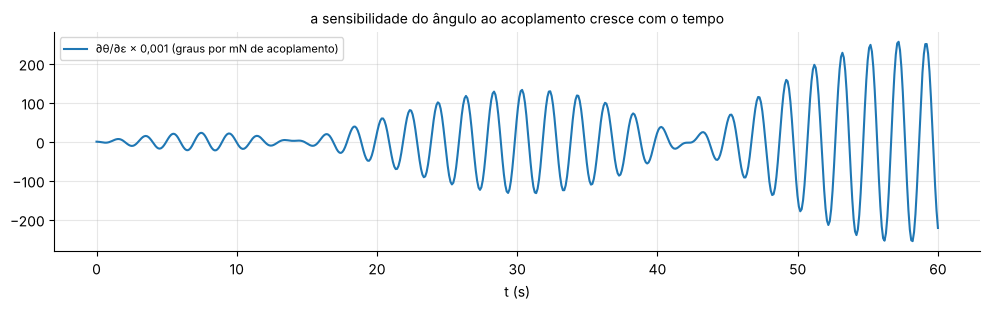

In [7]:
def f_wil_dual(ep):
    """Lado direito do Wilberforce com ε dual: devolve f(t, Y) com Y = Dual(array, array)."""
    def f(t, Y):
        z, th, vz, vth = (Dual(Y.re[i], Y.du[i]) for i in range(4))
        az = -(K_V * z + ep / 2 * th) / M_V
        ath = -(DL_V * th + ep / 2 * z) / I_V
        comp = [vz, vth, az, ath]
        return Dual(np.array([x.re for x in comp]), np.array([x.du for x in comp]))
    return f

def rk4_dual(f, Y, T, h):
    for i in range(int(round(T / h))):
        k1 = f(0, Y); k2 = f(0, Y + k1 * (h / 2)); k3 = f(0, Y + k2 * (h / 2)); k4 = f(0, Y + k3 * h)
        Y = Y + (k1 + k2 * 2 + k3 * 2 + k4) * (h / 6)
    return Y

T_s = 10.0
Y = rk4_dual(f_wil_dual(Dual(EP_V, 1.0)), Dual(y0.copy(), np.zeros(4)), T_s, 0.001)
A0 = matriz_A(); A1 = matriz_A(EP_V + 1.0) - matriz_A(EP_V)            # ∂A/∂ε (A é linear em ε)
blocos = expm(np.block([[A0, A1], [np.zeros((4, 4)), A0]]) * T_s)
sens_exata = blocos[:4, 4:] @ y0
print("sensibilidade ∂y(10 s)/∂ε, duais pelo RK4: ", Y.du)
print("sensibilidade ∂y(10 s)/∂ε, expm da matriz dual:", sens_exata)
confere("duais pelo RK4 = exponencial da matriz dual", Y.du, sens_exata, tol=1e-6, relativo=True)
confere("parte real dos duais = solução exata", Y.re, expm(A0 * T_s) @ y0, tol=1e-9, relativo=True)
dif = (expm(matriz_A(EP_V + 1e-7) * T_s) @ y0 - expm(matriz_A(EP_V - 1e-7) * T_s) @ y0) / 2e-7
print(f"diferenças finitas (h = 1e-7) erram {np.max(np.abs(dif - sens_exata)) / np.max(np.abs(sens_exata)):.1e} (relativo)")

ts2 = np.linspace(0, 60, 600)
S = np.array([(expm(np.block([[A0, A1], [np.zeros((4, 4)), A0]]) * ti)[:4, 4:] @ y0) for ti in ts2])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(ts2, np.degrees(S[:, 1]) * 1e-3, label="∂θ/∂ε × 0,001 (graus por mN de acoplamento)")
ax.set_xlabel("t (s)"); ax.legend(fontsize=8); ax.set_title("a sensibilidade do ângulo ao acoplamento cresce com o tempo", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Os dois caminhos concordam: o RK4 levou a parte dual junto, com a mesma precisão com que levou a parte real (a diferença relativa de $10^{-11}$ é o erro do próprio RK4 com passo de 1 ms). As diferenças finitas, aplicadas à solução exata, erram $10^{-9}$: perdem uns sete dígitos para o cancelamento. A figura mostra a sensibilidade do ângulo ao acoplamento ao longo de um minuto: ela oscila, modulada pelo batimento, com uma envoltória que cresce, porque mudar $\epsilon$ muda o período do batimento, e um erro de período se acumula com o tempo. É a razão pela qual **predições longas são frágeis**: uma pequena incerteza num parâmetro vira uma incerteza grande no estado, mais tarde. Um filtro de Kalman compensa isso corrigindo o estado com medidas, sempre.

---

## 5. Espaço de estados para a etapa (d)

Na etapa (d), Penélope anda na parede de um silo cilíndrico: o estado dela é a posição no cilindro, ângulo $\varphi$ e altura $z$, mais as velocidades. Pepé a modela com velocidade quase constante e aceleração aleatória, como nos domínios I e II, com uma diferença: a aceleração aleatória tem intensidade $q$ em m/s² ao longo da parede; em ângulo, num silo de raio $R$, ela vira $q/R^2$ (rad/s²)². Com o estado $(\varphi,z,\dot\varphi,\dot z)$, $\mathbf F$ e $\mathbf Q$ são as do domínio II com as intensidades $(q/R^2,\ q)$.

E a **predição** precisa respeitar o círculo: $\hat\varphi\leftarrow\hat\varphi\boxplus\dot{\hat\varphi}\,\Delta t$. Como $\mathbf F$ é linear e o grupo é comutativo, isso é o mesmo que aplicar $\mathbf F$ e enrolar o ângulo depois: a seção 3, com um passo só.

In [8]:
def discretiza(A, B, dt, q):
    """F = e^{AΔt} e Q = ∫ e^{As} B diag(q) Bᵀ e^{Aᵀs} ds (Van Loan, notebook I(c))."""
    n = A.shape[0]
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ np.diag(q) @ B.T; V[n:, n:] = A.T
    W = expm(V * dt); F = expm(A * dt)
    Q = F @ W[:n, n:]
    return F, 0.5 * (Q + Q.T)

R_SILO, Q_INT, DT = 5.0, 1.0, 0.1
A_cv = np.zeros((4, 4)); A_cv[0, 2] = A_cv[1, 3] = 1.0
B_cv = np.zeros((4, 2)); B_cv[2, 0] = B_cv[3, 1] = 1.0
F, Q = discretiza(A_cv, B_cv, DT, [Q_INT / R_SILO**2, Q_INT])
print("F =\n", F, "\nQ =\n", Q)
confere("Q do ângulo = Q da altura / R²", Q[np.ix_([0, 2], [0, 2])], Q[np.ix_([1, 3], [1, 3])] / R_SILO**2, tol=1e-15)

x = np.array([3.1, 4.0, 0.5, -0.2])                    # perto de π, girando no sentido positivo
x_pred = F @ x; x_pred[0] = wrap(x_pred[0])
print(f"\npredição: φ = {x[0]} → {x_pred[0]:.4f} (passou de π: enrolado para perto de −π)")
confere("predição com ⊞ = F e depois enrolar", x_pred[0], wrap(x[0] + DT * x[2]), tol=1e-15)

F =
 [[1.  0.  0.1 0. ]
 [0.  1.  0.  0.1]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]] 
Q =
 [[0.000013 0.       0.0002   0.      ]
 [0.       0.000333 0.       0.005   ]
 [0.0002   0.       0.004    0.      ]
 [0.       0.005    0.       0.1     ]]
OK   Q do ângulo = Q da altura / R²:  diferença máxima = 2.71e-20

predição: φ = 3.1 → -3.1332 (passou de π: enrolado para perto de −π)
OK   predição com ⊞ = F e depois enrolar:  diferença máxima = 0.00e+00


**Leitura.** A predição é a mesma dos domínios anteriores, mais o enrolamento. O cuidado novo, e o assunto da etapa (d), está na **correção**: quando a medida do ângulo e a predição estão em lados opostos de $\pm\pi$, a diferença entre elas (a inovação) tem de ser calculada com $\boxminus$, e não com a subtração.

---

## 6. Exercícios

1. **Wilberforce dessintonizado.** Mude $\delta$ para que $\delta/I$ seja 20% maior que $k/m$. A troca de energia continua completa? Encontre a fração máxima que passa para o giro em função da dessintonia, com o `sympy` (os modos normais dão a resposta).
2. **Euler semi-implícito.** Integre o Wilberforce com o Euler semi-implícito do notebook I(c) e passo $h=0{,}01$ s por 10 minutos. Compare a energia com a do RK4. Qual é melhor para simulações longas?
3. **Sensibilidade a todos os parâmetros.** Calcule $\partial\mathbf y(t)/\partial(m,I,k,\delta,\epsilon)$ com cinco passadas de duais. Qual parâmetro mais afeta o **período do batimento**? Confira com a fórmula dos modos normais.
4. **Hélice e passo.** Um parafuso com passo de 1 mm gira a 30 rotações por segundo. Escreva o movimento como $\mathrm{Exp}$ do domínio, com $\xi=(\omega,v)$. Qual é o **Log** do movimento depois de 1/60 s? E depois de 1/45 s? Por que o segundo surpreende?
5. **Atrito seco no giro.** Troque o atrito viscoso da seção 3 por atrito seco (notebook I(c), seção 4). A barra para depois de quantas voltas? A conferência RKMK = RK4 continua valendo?